# 08 · The combined detector: per-KPI CUSUM and coupled latency bank together

**Why.** Notebooks 05 and 07 found two complementary detectors:

- the **standard** per-stream CUSUM on all 11 KPIs, which is fast on traffic surges because it sees throughput;
- the **coupled** CUSUM bank on the three latencies, which is fast on small faults visible only in delay, such as a scheduling-weight misconfiguration.

**The combined detector** (`detectors.Union`) runs both and alarms as soon as either does. It is **calibrated jointly** to the same ARL of 1000 windows (100 s) as each detector alone: each part first gets half the false-alarm budget (ARL 2000 alone), then one factor sets the union to exactly 1000 (`eval.calibrate_union`). Its cost is slightly higher thresholds for each part; its benefit is covering both kinds of fault. This notebook measures both on the notebook-05 sweep (same seeds, all seven faults).

**Run it** from the project root (about 7 minutes):

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/08_combined_detector.ipynb
```

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUM, CUSUMBank, StreamModel, Union, candidate_directions, stream_array
from slicead.eval import calibrate_bank, calibrate_per_stream, calibrate_union, first_alarms, summarize_delays

SEED = 20261022                       # same seeds as notebooks 05-07
OUT = Path("../results/08_combined_detector")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"08_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"08_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"08_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLORS = {"standard (11 KPIs)": "#2a78d6", "coupled bank (latency)": "#eb6834", "combined": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
SLICES = ["eMBB", "URLLC", "mMTC"]
KPIS = ["throughput_mbps", "latency_ms", "jitter_ms", "loss_pct"]
STREAMS = [(s, k) for s in SLICES for k in KPIS if not (s == "URLLC" and k == "loss_pct")]
LAT = [STREAMS.index((s, "latency_ms")) for s in SLICES]
TARGET_ARL, CHANGE_S, HORIZON_W = 1000, 10.0, 300
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]

def detector_input(model, X):
    # columns 0-10: raw z-scores of the 11 KPIs (standard detector); 11-13: whitened latencies (bank)
    return np.concatenate([model.standardize(X), model.whiten(X)[:, :, LAT]], axis=2)
STD_COLS, LAT_COLS = list(range(11)), [11, 12, 13]

## 1. Calibration

In [2]:
t0 = time.time()
train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
calib = simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1)
model = StreamModel().fit(stream_array(train, STREAMS))
Zcal = detector_input(model, stream_array(calib, STREAMS))
Sigma = np.corrcoef(detector_input(model, stream_array(train, STREAMS))[:, :, LAT_COLS].reshape(-1, 3).T)

standard = CUSUM(0.5)
c_std, _ = calibrate_per_stream(standard, Zcal[:, :, STD_COLS], TARGET_ARL)
bank = CUSUMBank(candidate_directions(3), Sigma)
c_bank, _ = calibrate_bank(bank, Zcal[:, :, LAT_COLS], TARGET_ARL)

# the combined detector uses its own copies, so the stand-alone detectors keep their thresholds
std_part, bank_part = CUSUM(0.5), CUSUMBank(candidate_directions(3), Sigma)
std_part.scale, bank_part.scale = standard.scale.copy(), bank.scale.copy()
combined = Union([(std_part, STD_COLS, c_std), (bank_part, LAT_COLS, c_bank)], sizes=[11, 20])
c_comb, arl_comb = calibrate_union(combined, Zcal, TARGET_ARL)
print(f"calibrated in {time.time() - t0:.0f} s")
print(f"stand-alone thresholds: standard {c_std:.3f}, bank {c_bank:.3f}")
print(f"inside the union (ARL 2000 each): standard {combined.parts[0][2]:.3f}, bank {combined.parts[1][2]:.3f}; "
      f"final factor {c_comb:.3f}, ARL {arl_comb:.0f}")

calibrated in 129 s
stand-alone thresholds: standard 0.945, bank 0.978
inside the union (ARL 2000 each): standard 1.039, bank 1.023; final factor 0.991, ARL 1000


## 2. The sweep

In [3]:
SCENARIOS = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
NICE = {"capacity_drop": "capacity drop", "capacity_degradation": "capacity degradation",
        "embb_surge": "eMBB surge", "urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm",
        "urllc_loss_burst": "URLLC loss burst", "urllc_weight_misconfig": "URLLC weight misconfig."}
DETS = {"standard (11 KPIs)": (standard, STD_COLS, c_std), "coupled bank (latency)": (bank, LAT_COLS, c_bank),
        "combined": (combined, list(range(14)), c_comb)}

def scaled(faults, s):
    return [Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in faults]

rows, part_hits = [], []
t0 = time.time()
for i, (scen, faults) in enumerate(SCENARIOS.items()):
    for j, s in enumerate(STRENGTHS):
        res = simulate(cfg, n_windows=400, n_runs=32, seed=SEED + 100 + 10 * i + j, faults=scaled(faults, s))
        Z = detector_input(model, stream_array(res, STREAMS))
        for name, (det, cols, c) in DETS.items():
            t_alarm, which = first_alarms(det, Z[:, :, cols], c)
            rows.append(dict(scenario=NICE[scen], strength=s, detector=name,
                             **summarize_delays(t_alarm, res.fault_window, HORIZON_W, res.window_s)))
            if name == "combined":
                hit = t_alarm >= res.fault_window
                parts = [combined.decode(int(w))[0] for w in which[hit]]
                part_hits.append(dict(scenario=NICE[scen], strength=s,
                                      share_bank=np.mean(parts) if parts else np.nan))
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "sweep.csv", index=False)
part_hits = pd.DataFrame(part_hits)
print(f"sweep simulated and scored in {time.time() - t0:.0f} s")

# consistency with notebooks 05 and 07 (same seeds, same detectors)
nb05 = pd.read_csv("../results/05_detectors/sweep.csv")
nb05 = nb05[(nb05.thresholds == "equalised") & (nb05.detector == "CUSUM, raw")].set_index(["scenario", "strength"]).delay_mean_s
mine = sweep[sweep.detector == "standard (11 KPIs)"].set_index(["scenario", "strength"]).delay_mean_s
print("standard vs notebook 05, max |difference|:", float((mine - nb05.reindex(mine.index)).abs().max()))
nb07 = pd.read_csv("../results/07_coupled_detectors/sweep.csv")
nb07 = nb07[nb07.detector == "CUSUM bank"].set_index(["scenario", "strength"]).delay_mean_s
mine = sweep[sweep.detector == "coupled bank (latency)"].set_index(["scenario", "strength"]).delay_mean_s
print("bank vs notebook 07, max |difference|:", float((mine - nb07.reindex(mine.index)).dropna().abs().max()))
sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s").round(1)

sweep simulated and scored in 240 s


standard vs notebook 05, max |difference|: 3.552713678800501e-15
bank vs notebook 07, max |difference|: 3.552713678800501e-15


detector                          combined  coupled bank (latency)  \
scenario                strength                                     
URLLC loss burst        0.03          27.6                    26.5   
                        0.10          21.9                    24.3   
                        0.25          25.3                    25.5   
                        0.50          27.9                    26.8   
                        1.00          28.6                    27.5   
URLLC surge             0.03           3.0                    23.3   
                        0.10           0.4                     3.3   
                        0.25           0.2                     0.2   
                        0.50           0.1                     0.1   
                        1.00           0.1                     0.1   
URLLC weight misconfig. 0.03          17.4                    16.9   
                        0.10           0.4                     0.4   
                        0.25           0.1                     0.1   
                        0.50           0.1                     0.1   
                        1.00           0.1                     0.1   
capacity degradation    0.03          28.5                    28.1   
                        0.10          26.7                    28.3   
                        0.25          26.8                    25.4   
                        0.50          21.5                    22.6   
                        1.00          17.3                    19.3   
capacity drop           0.03          26.5                    26.9   
                        0.10          22.1                    21.9   
                        0.25          11.9                    15.6   
                        0.50           3.5                     5.6   
                        1.00           0.7                     0.6   
eMBB surge              0.03          24.9                    25.9   
                        0.10          23.2                    24.9   
                        0.25          24.5                    25.4   
                        0.50          15.0                    26.2   
                        1.00           4.6                    18.1   
mMTC storm              0.03           0.9                    23.7   
                        0.10           0.2                     2.9   
                        0.25           0.1                     0.1   
                        0.50           0.1                     0.1   
                        1.00           0.1                     0.1   

detector                          standard (11 KPIs)  
scenario                strength                      
URLLC loss burst        0.03                    25.2  
                        0.10                    24.7  
                        0.25                    26.8  
                        0.50                    27.4  
                        1.00                    26.6  
URLLC surge             0.03                     2.7  
                        0.10                     0.4  
                        0.25                     0.2  
                        0.50                     0.1  
                        1.00                     0.1  
URLLC weight misconfig. 0.03                    21.6  
                        0.10                     4.1  
                        0.25                     0.9  
                        0.50                     0.3  
                        1.00                     0.1  
capacity degradation    0.03                    27.5  
                        0.10                    26.3  
                        0.25                    27.4  
                        0.50                    23.3  
                        1.00                    17.0  
capacity drop           0.03                    27.9  
                        0.10                    22.6  
                        0.25                    11.4  
                        0.50      

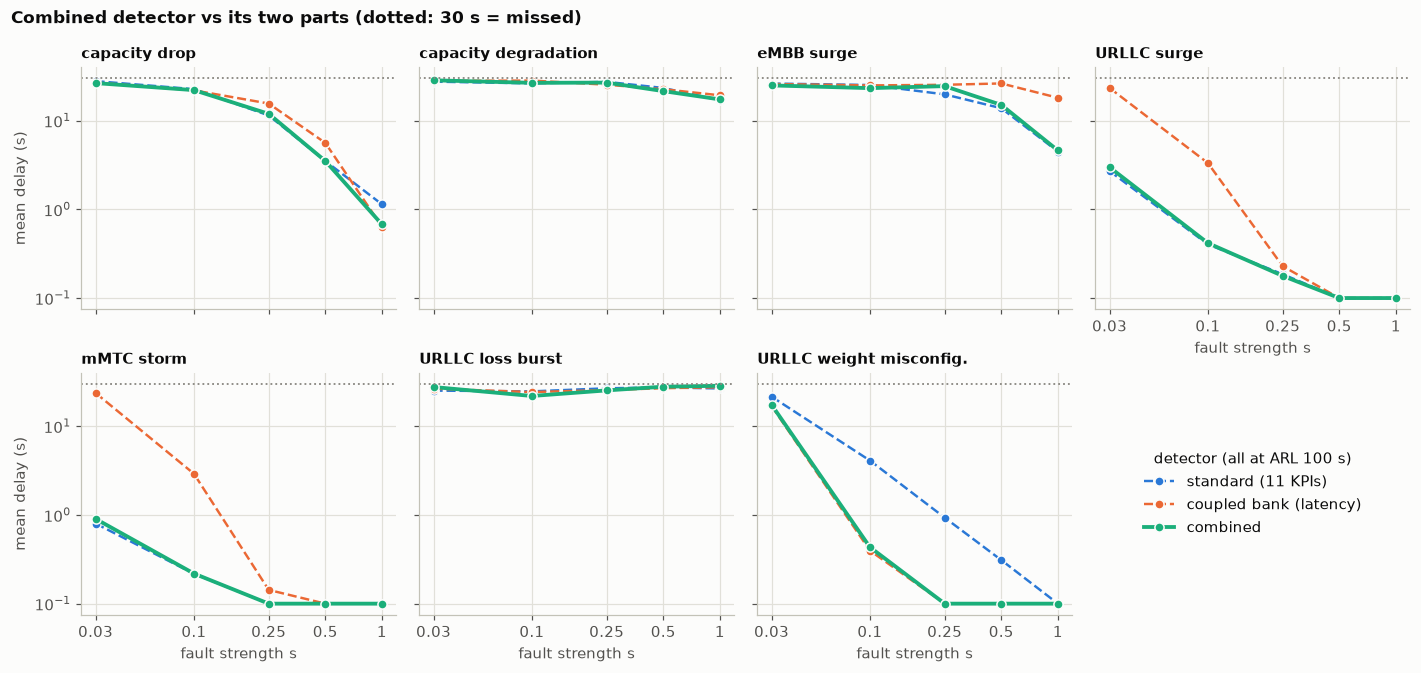

In [4]:
order = list(NICE.values())
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, scen in zip(axes.ravel(), order):
    g = sweep[sweep.scenario == scen]
    for det, col in COLORS.items():
        d = g[g.detector == det].sort_values("strength")
        ax.plot(d.strength, d.delay_mean_s, marker="o", color=col, label=det, mec=SURFACE, mew=1,
                ls="-" if det == "combined" else "--", lw=2.5 if det == "combined" else 1.6)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axhline(30, color=MUTED, ls=":", lw=1.2)
    ax.set_title(scen, fontsize=10)
    ax.set_xticks(STRENGTHS, [f"{s:g}" for s in STRENGTHS]); ax.minorticks_off()
axes.ravel()[-1].axis("off")
h, l = axes[0, 0].get_legend_handles_labels()
axes.ravel()[-1].legend(h, l, loc="center", title="detector (all at ARL 100 s)")
for ax in axes[1]:
    ax.set_xlabel("fault strength s")
axes[0, 3].set_xlabel("fault strength s"); axes[0, 3].xaxis.set_tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("mean delay (s)")
fig.suptitle("Combined detector vs its two parts (dotted: 30 s = missed)", x=0.01, ha="left", fontsize=11,
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig1_combined_sweep")
plt.show()

## 3. How close is the combination to the better part?

For each fault and strength, compare the combined delay with the **better** of the two detectors on their own. That "oracle choice" would need to know the fault type in advance. A ratio near 1 means combining costs little; the price of splitting the false-alarm budget shows up as a ratio somewhat above 1.

In [5]:
P = sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s")
best = P[["standard (11 KPIs)", "coupled bank (latency)"]].min(axis=1)
cmp = pd.DataFrame({"best single": best, "combined": P["combined"], "combined / best": P["combined"] / best,
                    "combined / standard": P["combined"] / P["standard (11 KPIs)"]})
cmp = cmp.join(part_hits.set_index(["scenario", "strength"]))
cmp.to_csv(OUT / "comparison.csv")
overall = sweep.groupby("detector").agg(mean_delay=("delay_mean_s", "mean"), detected=("detected", "mean"))
display(overall.round(2))
cmp.round(2)

,mean_delay,detected
detector,,
combined,12.36,0.71
coupled bank (latency),14.77,0.63
standard (11 KPIs),12.57,0.70


best single  combined  combined / best  \
scenario                strength                                           
URLLC loss burst        0.03            25.19     27.65             1.10   
                        0.10            24.28     21.92             0.90   
                        0.25            25.54     25.35             0.99   
                        0.50            26.83     27.89             1.04   
                        1.00            26.62     28.58             1.07   
URLLC surge             0.03             2.70      2.98             1.10   
                        0.10             0.40      0.42             1.03   
                        0.25             0.19      0.18             0.96   
                        0.50             0.10      0.10             1.00   
                        1.00             0.10      0.10             1.00   
URLLC weight misconfig. 0.03            16.92     17.44             1.03   
                        0.10             0.40      0.43             1.09   
                        0.25             0.10      0.10             1.00   
                        0.50             0.10      0.10             1.00   
                        1.00             0.10      0.10             1.00   
capacity degradation    0.03            27.50     28.47             1.04   
                        0.10            26.29     26.68             1.01   
                        0.25            25.39     26.81             1.06   
                        0.50            22.60     21.51             0.95   
                        1.00            16.98     17.34             1.02   
capacity drop           0.03            26.89     26.48             0.98   
                        0.10            21.95     22.08             1.01   
                        0.25            11.44     11.93             1.04   
                        0.50             3.51      3.51             1.00   
                        1.00             0.64      0.68             1.06   
eMBB surge              0.03            25.86     24.94             0.96   
                        0.10            24.94     23.24             0.93   
                        0.25            19.77     24.48             1.24   
                        0.50            13.80     15.03             1.09   
                        1.00             4.48      4.61             1.03   
mMTC storm              0.03             0.80      0.90             1.13   
                        0.10             0.22      0.22             1.01   
                        0.25             0.10      0.10             1.00   
                        0.50             0.10      0.10             1.00   
                        1.00             0.10      0.10             1.00   

                                  combined / standard  share_bank  
scenario                strength                                   
URLLC loss burst        0.03                     1.10        0.80  
                        0.10                     0.89        0.45  
                        0.25                     0.95        0.67  
                        0.50                     1.02        0.17  
                        1.00                     1.07        0.67  
URLLC surge             0.03                     1.10        0.06  
                        0.10                     1.03        0.13  
                        0.25                     0.96        0.22  
                        0.50                     1.00        0.72  
                        1.00                     1.00        0.73  
URLLC weight misconfig. 0.03                     0.81        0.81  
                        0.10                     0.11        1.00  
                        0.25                     0.11        1.00  
                        0.50                     0.32        1.00  
                        1.00                     1.00        1.00  
capacity degradation    0.03                     1.04        0.57

**What it shows**

- **The combined detector is as fast as the better of its two parts, for every fault, without knowing which fault it is.** Across all 35 fault-and-strength cells, its delay divided by the better single detector's delay has a median of 1.00, and lies within about ±10% everywhere except one cell near chance level (eMBB surge at $s = 0.25$, 1.24).
- **It keeps each part's strength:**
  - **Weight misconfiguration ($s = 0.1$):** 0.43 s, against 4.1 s for the standard detector. The bank part fires in 100% of these detections.
  - **URLLC surge ($s = 0.1$):** 0.42 s, against 3.3 s for the bank. The standard part fires in most of these detections.
  - **Small mMTC storm ($s = 0.03$):** 0.9 s, against 23.7 s for the bank.
- **The cost of combining is small.** Giving each part half the false-alarm budget raises their thresholds by only about 4–10% (standard 0.945 → 1.039, bank 0.978 → 1.023), and the delay penalty is within Monte Carlo noise in most cells.
- **Overall it is the best detector of the three:** mean delay over the sweep 12.4 s (standard 12.6 s, bank 14.8 s), detection rate 0.71 (0.70, 0.63).
- **Shared faults and the loss burst are not helped.** Neither part detects them better, so the union cannot either.

In [6]:
# Export tables and key numbers for report/main.tex
rows = []
for scen in order:
    for s in STRENGTHS:
        r = {"fault": scen, "$s$": f"{s:g}"}
        for d in COLORS:
            g = sweep[(sweep.scenario == scen) & (sweep.strength == s) & (sweep.detector == d)].iloc[0]
            r[d] = f"{g.delay_mean_s:.1f}" if g.detected >= 0.995 else f"{g.delay_mean_s:.1f} ({100 * g.detected:.0f}\\%)"
        rows.append(r)
tab = pd.DataFrame(rows)
tab["fault"] = [f if i == 0 or f != tab.fault[i - 1] else "" for i, f in enumerate(tab.fault)]
tab.columns = ["fault", "$s$", "standard", "coupled bank", "combined"]
save_tex_table(tab, "sweep", "llrrr")

def d(scen, s, det):
    return sweep[(sweep.scenario == scen) & (sweep.strength == s) & (sweep.detector == det)].delay_mean_s.iloc[0]
ok = cmp[cmp["best single"] < 25]          # cells where at least one detector really detects
save_tex_numbers({
    "CombMeanStd": f"{overall.loc['standard (11 KPIs)', 'mean_delay']:.1f}",
    "CombMeanBank": f"{overall.loc['coupled bank (latency)', 'mean_delay']:.1f}",
    "CombMeanComb": f"{overall.loc['combined', 'mean_delay']:.1f}",
    "CombMisStd": f"{d('URLLC weight misconfig.', 0.1, 'standard (11 KPIs)'):.1f}",
    "CombMisBank": f"{d('URLLC weight misconfig.', 0.1, 'coupled bank (latency)'):.1f}",
    "CombMisComb": f"{d('URLLC weight misconfig.', 0.1, 'combined'):.1f}",
    "CombSurgeStd": f"{d('URLLC surge', 0.1, 'standard (11 KPIs)'):.1f}",
    "CombSurgeBank": f"{d('URLLC surge', 0.1, 'coupled bank (latency)'):.1f}",
    "CombSurgeComb": f"{d('URLLC surge', 0.1, 'combined'):.1f}",
    "CombRatioMedian": f"{ok['combined / best'].median():.2f}",
    "CombRatioMax": f"{ok['combined / best'].max():.2f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("08_*")))

exported: ['08_numbers.tex', '08_sweep.tex']


## 4. Summary

- **The combined detector is the project's recommended detector.** It runs the per-KPI CUSUM on all 11 KPIs and the coupled latency bank, alarms when either fires, and is calibrated jointly to the same false-alarm rate.
- **It matches the better part on every fault** (median ratio 1.00): fast on traffic surges through throughput, and about 10× faster than the standard detector on the delay-only weight misconfiguration.
- **Remaining gaps:** shared capacity faults below about 8% (no KPI here carries enough information), and the URLLC loss burst (needs a count model).